# Lasso (classification) Hyperparameter Tuning Using Mother

In this example we will outline how easy another ML algorithm can be used as a base model for hyperparameter tuning. At this stage, 3 different algorithms are supported within mother out of the box. However, as you can see in the 'models' folder, it is very easy to provide additional models very easily.

In [1]:
import logging
import tempfile
from pathlib import Path

import pandas as pd

# plt.cla()
import seaborn as sns
from IPython.display import Image, display

# import matplotlib
# matplotlib.use("TkAgg")
from matplotlib import pyplot as plt
from sklearn import metrics
from sklearn import pipeline as sklearn_pipeline
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import GroupKFold, KFold
from sklearn.preprocessing import StandardScaler

import mother.ml as ml
import mother.optimization as opt
import mother.pipeline_utils as mother_takes_care
from mother import cv as cv_module
from mother import feature_generation as fg
from mother.cv import report as cv_report
from mother.ml.models.m_lasso import LassoClassifierMother
from mother.optimization.report import optuna_qc
from mother.preprocessing import SmilesToMolTransformer, StandardizerTransformer

# Ensure plots are displayed inline
%matplotlib inline
logging.basicConfig(level=logging.INFO)

In [2]:
ml.get_available_algorithms()

INFO:mother.ml:Loaded 14 model classes: NODEClassifier, NODERegressor, LassoClassifierMother, LassoRegressorMother, TabICLClassifierMother, TabICLRegressorMother, RandomForestClassifierMother, RandomForestRegressorMother, TabPFNClassifierMother, TabPFNRegressorMother, CatboostClassifierMother, CatboostGaussianProcessRegressorMother, CatboostRankerMother, CatboostRegressorMother


['node', 'lasso', 'tabicl', 'randomforest', 'tabpfn', 'catboost']

In [3]:
print(*ml.get_supported_models(), sep=" -- ")

NODEClassifier -- NODERegressor -- LassoClassifierMother -- LassoRegressorMother -- TabICLClassifierMother -- TabICLRegressorMother -- RandomForestClassifierMother -- RandomForestRegressorMother -- TabPFNClassifierMother -- TabPFNRegressorMother -- CatboostClassifierMother -- CatboostGaussianProcessRegressorMother -- CatboostRankerMother -- CatboostRegressorMother


In [4]:
selected_model: str = "LassoClassifierMother"

In [5]:
print(ml.describe_model(selected_model))

## LassoClassifierMother

MOTHER class for a LASSO (L1-regularised logistic regression) classification of binary and
multiclass targets, including hyperparameter optimization.

As in the other MOTHER models, the target type is not detected from the data but set explicitly
with ``target_type``; in a pipeline built from settings it is taken from
``settings.model.target_type``. ``LogisticRegression`` fits one target column (binary or
multiclass), so only ``target_type="single_target"`` is supported. A multi-target setting or a
target with more than one column raises a ``ValueError``.

With ``solver="auto"`` (default) the solver is chosen at fit time: ``liblinear`` for binary targets
and ``saga`` for multiclass targets, the only scikit-learn solver that supports pure L1 for
multinomial problems. The chosen solver is stored in ``solver_``; the ``solver`` parameter keeps
the value passed by the user. An explicitly passed solver is used as given.

``saga`` converges much better on standardise

In [6]:
ml.get_model_class(selected_model)

mother.ml.models.m_lasso.LassoClassifierMother

### Import Data
Load the data from the input file and limit the data to 100 rows for testing purposes.
The data file contains a column with the molecular structure (__Molecule__) and a column with the target value (__expt__).



In [7]:
input_file: Path = Path("../compounds_class_1.csv")
data: pd.DataFrame = pd.read_csv(input_file, sep=",")
# data = data.head(100)  # limit data to 100 rows for testing
data = data[["name", "smiles", "p_np"]]
data.head()

,name,smiles,p_np
0,"""1,1,1-Trifluro-2-chloroethane""",FC(F)(F)CCl,1
1,111-trichloroethane,CC(Cl)(Cl)Cl,1
2,111-trifluoro-2-chloroethane,FC(F)(F)CCl,1
3,2-Methylpentane,CCCC(C)C,1
4,3-methylhexane,CCCC(C)CC,1


<Axes: xlabel='p_np', ylabel='Count'>

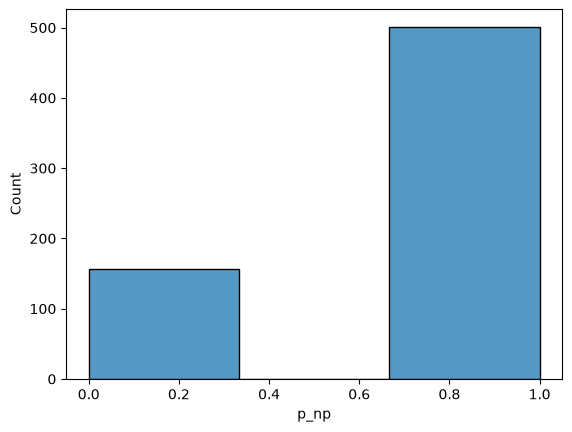

In [8]:
sns.histplot(data=data, x="p_np", bins=3)

In [9]:
len(data)

657

## Preprocessing
The preprocessing pipeline consists of two steps:
1. Standardize the molecular structure using the __StandardizerTransformer__.
2. Convert the standardized SMILES to a molecule object using the __SmilesToMolTransformer__.

In [10]:
preprocessor: sklearn_pipeline.Pipeline = sklearn_pipeline.Pipeline(
    [
        (
            "smiles_standardizer",
            StandardizerTransformer(flags=["STANDARDIZE", "NEUTRALIZE", "DESALT"]),
        ),
        ("smiles_to_mol", SmilesToMolTransformer()),
        # Add other column transformations here if needed
    ],
    memory=None,
).set_output(transform="pandas")  # type: ignore

structure_data: pd.Series = data["smiles"]
mol_data: pd.DataFrame = preprocessor.fit_transform(structure_data)  # type: ignore

mol_data.head()

INFO:mother.preprocessing.core:Standardizing SMILES with flags: ['STANDARDIZE', 'NEUTRALIZE', 'DESALT']
[17:49:09] Initializing Normalizer
[17:49:09] Initializing MetalDisconnector
[17:49:09] Initializing Normalizer
ERROR:mother.preprocessing.core:Catched exception from RDKit during standardization of SMILES with INDEX: 384


,Molecule
0,<rdkit.Chem.rdchem.Mol object at 0x7f8dc78d0900>
1,<rdkit.Chem.rdchem.Mol object at 0x7f8dc78d05f0>
2,<rdkit.Chem.rdchem.Mol object at 0x7f8dc78d0820>
3,<rdkit.Chem.rdchem.Mol object at 0x7f8dc78d09e0>
4,<rdkit.Chem.rdchem.Mol object at 0x7f8dc78d07b0>


In [11]:
print(mol_data.shape)
mol_data.dropna(subset="Molecule", inplace=True, axis=0)
print(mol_data.shape)

(657, 1)
(657, 1)


## Feature Generation
By combining multiple feature generators, we can create a feature matrix that contains various types of features. By default, we are combining _MACCS_ fingerprints, _Morgan_ fingerprints, and _Chemical Descriptors_.

In [12]:
feature_generator = sklearn_pipeline.FeatureUnion(
    transformer_list=[
        ("maccs", fg.MaccsFingerprints()),
        ("morgan", fg.MorganFingerprints()),
        ("desc", fg.ChemicalDescriptors()),
    ],
).set_output(transform="pandas")


features: pd.DataFrame = feature_generator.fit_transform(mol_data["Molecule"])

features.head()

INFO:mother.feature_generation.core:Calculating MACCS fingerprints
INFO:mother.feature_generation.core:Calculating MorganFP fingerprints using parameters: {'radius': 2, 'fpSize': 2048, 'includeChirality': False}
INFO:mother.feature_generation.fp_gen:Creating fingerprint generator 'MorganFP'


,maccs__maccs_0,maccs__maccs_1,maccs__maccs_2,maccs__maccs_3,maccs__maccs_4,maccs__maccs_5,maccs__maccs_6,maccs__maccs_7,maccs__maccs_8,maccs__maccs_9,...,desc__fr_sulfide,desc__fr_sulfonamd,desc__fr_sulfone,desc__fr_term_acetylene,desc__fr_tetrazole,desc__fr_thiazole,desc__fr_thiocyan,desc__fr_thiophene,desc__fr_unbrch_alkane,desc__fr_urea
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Grouping for Cross-Validation
To ensure that the training and validation sets do not contain similar molecules, we group the molecules based on their similarity. We use the Tanimoto similarity to group molecules with a similarity threshold of 0.7. 

In [13]:
# cv grouping
groups_engine = cv_module.TanimotoGroupingFromMols(similarity_threshold=0.3)

groups: pd.DataFrame = groups_engine.set_output(transform="pandas").fit_transform(mol_data["Molecule"])

# cv = StratifiedGroupKFold(n_splits=5)
cv = GroupKFold(n_splits=5)

print(f"{groups['tanimoto-group'].nunique()} groups found")

INFO:mother.feature_generation.fp_gen:Creating fingerprint generator 'MorganFP'
INFO:mother.cv.cv_methods:Applying clustering with Tanimoto similarity: 0.3
INFO:mother.cv.cv_methods:Found: 274 clusters


274 groups found


<Axes: title={'center': 'GroupKFold  (274 groups; each group entirely in train or test)'}, xlabel='Sample index (sorted by group)', ylabel='CV iteration'>

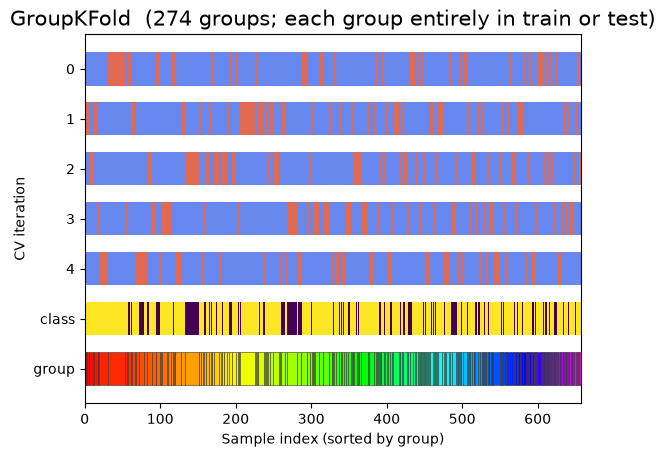

In [14]:
cv_report.plot_cv_indices(cv=cv, X=features, y=data["p_np"], group=groups["tanimoto-group"], n_splits=5)

## Model Training
The model consists of two steps:
1. Feature selection using the __FeatureSelector__
2. Model training using the __LassoClassifierMother__

In [15]:
model_settings = {
    "feature_selection_flags": ["DROP_CORRELATED", "DROP_CONSTANT", "DROP_DUPLICATES"],
    "feature_selection_threshold": 1e-5,
    "correlation_threshold": 0.9,
    "algorithm": "lasso",
    "feature_selection_type": "catboost",
}
pipeline_settings = {
    "remainder": "passthrough",
    "verbose_feature_names_out": False,
}
model_settings["model_type"] = "classification"
model_settings["target_type"] = "single_target"
# lasso parameters
model_settings["parameters"] = {
    "C": 1,  # Regularization strength
    "max_iter": 3000,  # Maximum number of iterations for convergence
    "tol": 1e-4,  # Tolerance for stopping criteria
    "solver": "auto",  # liblinear for binary, saga for multiclass targets
}

model = ml.PipelineWithHyperparameterRooting(
    [
        (
            "feature_selector",
            mother_takes_care.get_feature_selection_pipeline(
                settings=model_settings, pipeline_settings=pipeline_settings
            ),
        ),
        ("scaler", StandardScaler()),
        ("ml_model", LassoClassifierMother(**model_settings["parameters"])),
    ]
).set_output(transform="pandas")

# fit the model to data
model.fit(features, data["p_np"])

targets_pred = model.predict(features)

INFO:mother.pipeline_utils:Creating feature selection pipeline for numeric columns.
INFO:mother.pipeline_utils:The default correlation method is used


In [16]:
# compare the predicted values with the experimental values
pd.concat((data["p_np"], pd.Series(targets_pred, name="p_np_pred")), axis=1)

,p_np,p_np_pred
0,1,1
1,1,1
2,1,1
3,1,1
4,1,1
...,...,...
652,1,1
653,1,1
654,1,1
655,1,1


In [17]:
%matplotlib inline

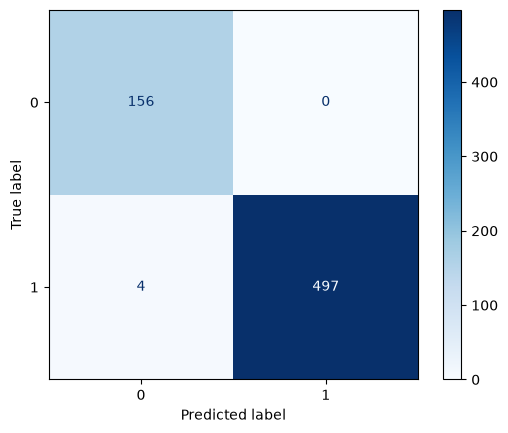

In [18]:
sns.reset_defaults()
y_true = data["p_np"]
y_pred = model.predict(features)

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")

plt.show()

In [19]:
def calc_metrics(labels_test, test_probs, threshold=0.5):
    scores = [1 if x >= threshold else 0 for x in test_probs]
    auc = metrics.roc_auc_score(labels_test, test_probs)
    kappa = metrics.cohen_kappa_score(labels_test, scores)
    confusion = metrics.confusion_matrix(labels_test, scores, labels=list(set(labels_test)))
    logging.info(f"thresh: {threshold:.2f}, kappa: {kappa:.3f}, AUC test-set: {auc:.3f}")
    logging.info(f"\n {confusion}")
    logging.info(f"\n {metrics.classification_report(labels_test, scores)}")


test_probs = model.predict_proba(features)[:, 1]
calc_metrics(data["p_np"].to_numpy(), test_probs, threshold=0.5)

INFO:root:thresh: 0.50, kappa: 0.983, AUC test-set: 1.000
INFO:root:
 [[156   0]
 [  4 497]]
INFO:root:
               precision    recall  f1-score   support

           0       0.97      1.00      0.99       156
           1       1.00      0.99      1.00       501

    accuracy                           0.99       657
   macro avg       0.99      1.00      0.99       657
weighted avg       0.99      0.99      0.99       657



## Cross-Validation
To evaluate the model's performance, we perform cross-validation using the grouped molecules.

In [20]:
cross_val_scores: pd.DataFrame = mother_takes_care.mother_cv(
    estimator=model, X=features, y=data["p_np"], groups=groups["tanimoto-group"], cv=cv
)
cross_val_scores

INFO:mother.pipeline_utils:Starting cross validation...
INFO:mother.pipeline_utils:Cross validation completed
INFO:mother.pipeline_utils:Returning performance_data only


,pred_p_np,pred_proba_0,pred_proba_1,pred_total_uncertainty,p_np,cv_group,iteration,test_index
0,1,0.003416,0.996584,0.022811,1,0,4,0
1,1,0.004615,0.995385,0.029428,1,1,1,1
2,1,0.003416,0.996584,0.022811,1,0,4,2
3,1,0.008497,0.991503,0.048977,1,2,1,3
4,1,0.007944,0.992056,0.046324,1,2,1,4
...,...,...,...,...,...,...,...,...
652,1,0.002939,0.997061,0.020067,1,270,0,652
653,1,0.008284,0.991716,0.047957,1,271,1,653
654,0,0.827304,0.172696,0.460136,1,263,3,654
655,1,0.000044,0.999956,0.000481,1,272,0,655


## Hyperparameter Optimization
To optimize the hyperparameters of the model, we use the __MotherTuner__. The tuner uses the models own __get_hyperparameter_space__ function to define the hyperparams, theirs bounds and transformations. If needed, this function can be overwritten to define custom hyperparameters.

The cross-val splits are used for the hyperparameter optimization. After the optimization, the model is retrained on the whole dataset.


In [21]:
model

,steps,"[('feature_selector', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](2432,)","['maccs__maccs_0','maccs__maccs_1','maccs__maccs_2',..., 'desc__fr_thiophene','desc__fr_unbrch_alkane','desc__fr_urea']"
n_features_in_,int,2432
,transformers,"[('feature_selector', ...)]"
,remainder,'passthrough'
,verbose_feature_names_out,False


In [22]:
model.default_parameters()

{'ml_model__C': 1.0}

In [23]:
metrics.get_scorer_names()

['accuracy',
 'adjusted_mutual_info_score',
 'adjusted_rand_score',
 'average_precision',
 'balanced_accuracy',
 'completeness_score',
 'd2_absolute_error_score',
 'd2_brier_score',
 'd2_log_loss_score',
 'explained_variance',
 'f1',
 'f1_macro',
 'f1_micro',
 'f1_samples',
 'f1_weighted',
 'fowlkes_mallows_score',
 'homogeneity_score',
 'jaccard',
 'jaccard_macro',
 'jaccard_micro',
 'jaccard_samples',
 'jaccard_weighted',
 'matthews_corrcoef',
 'mutual_info_score',
 'neg_brier_score',
 'neg_log_loss',
 'neg_max_error',
 'neg_mean_absolute_error',
 'neg_mean_absolute_percentage_error',
 'neg_mean_gamma_deviance',
 'neg_mean_poisson_deviance',
 'neg_mean_squared_error',
 'neg_mean_squared_log_error',
 'neg_median_absolute_error',
 'neg_negative_likelihood_ratio',
 'neg_root_mean_squared_error',
 'neg_root_mean_squared_log_error',
 'normalized_mutual_info_score',
 'positive_likelihood_ratio',
 'precision',
 'precision_macro',
 'precision_micro',
 'precision_samples',
 'precision_weighte

In [24]:
# scorer = make_scorer(score_func=matthews_corrcoef, greater_is_better=True, needs_proba=False)

# n_threads_optuna is the number of parallel threads for hyperparameter optimization
# so it should not be higher then the number of cross-validation folds
tuner = opt.MotherTuner(
    n_threads_optuna=2,
    scorer="f1",
    n_trials_optuna=10,
    n_startup_trials=10,
)


model_tuned = tuner.optimize(
    model,
    features,
    data["p_np"],
    cv,
    hyperparameter_space_function=model.get_hyperparameter_space,
    default_parameters=model.default_parameters(),
    groups=groups["tanimoto-group"],
)

src/mother/optimization/core.py:170: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  self.sampler = optuna.samplers.TPESampler(
src/mother/optimization/core.py:170: ExperimentalWarning: Argument ``group`` is an experimental feature. The interface can change in the future.
  self.sampler = optuna.samplers.TPESampler(
src/mother/optimization/core.py:170: ExperimentalWarning: Argument ``constant_liar`` is an experimental feature. The interface can change in the future.
  self.sampler = optuna.samplers.TPESampler(
INFO:mother.optimization.core:Setting up Optuna to optimize hyperparameters with direction: 2
INFO:optuna.storages._in_memory:A new study created in memory with name: no-name-1ee776e1-13c8-4947-aca7-e173d3735406
INFO:mother.optimization.core:Running hyperparameter optimization with 10 trials
INFO:mother.optimization.core:Trial 0, cv score: [0.89719626 0.85844749 0.84269663 0.86631016 0.91089109]
src/mother/optim

{'ml_model__C': 4.518560951024111}


INFO:mother.optimization.core:Training completed


In [25]:
targets_pred = model_tuned.predict(features)

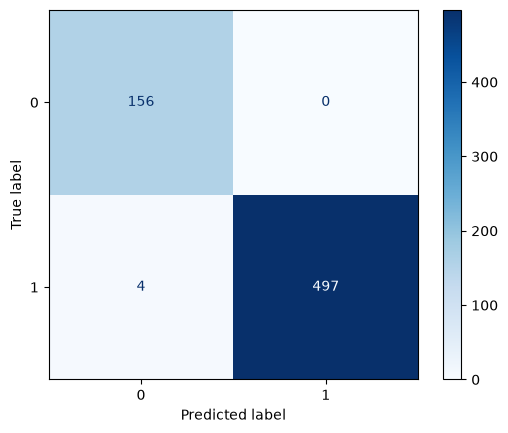

In [26]:
y_true = data["p_np"]
y_pred = targets_pred

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.show()

INFO:mother.optimization.report.optuna_qc:Plotting optuna results
src/mother/optimization/report/optuna_qc.py:33: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  axes: Axes = optuna.visualization.matplotlib.plot_optimization_history(study)
src/mother/optimization/report/optuna_qc.py:39: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  axes = optuna.visualization.matplotlib.plot_param_importances(
src/mother/optimization/report/optuna_qc.py:52: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  axis = optuna.visualization.matplotlib.plot_slice(study)
src/mother/optimization/report/optuna_qc.py:62: ExperimentalWarning: optuna.

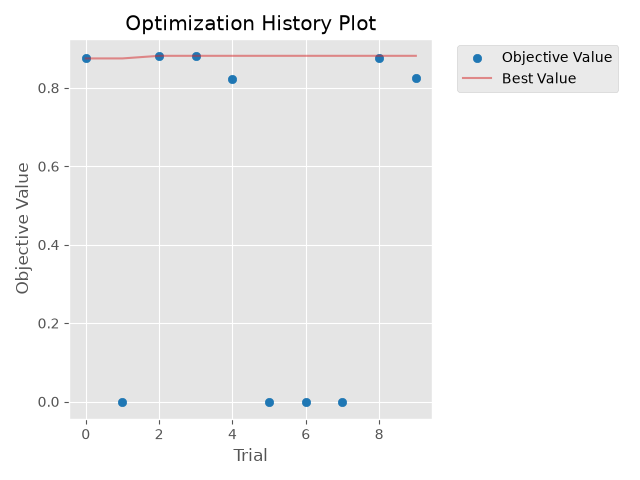

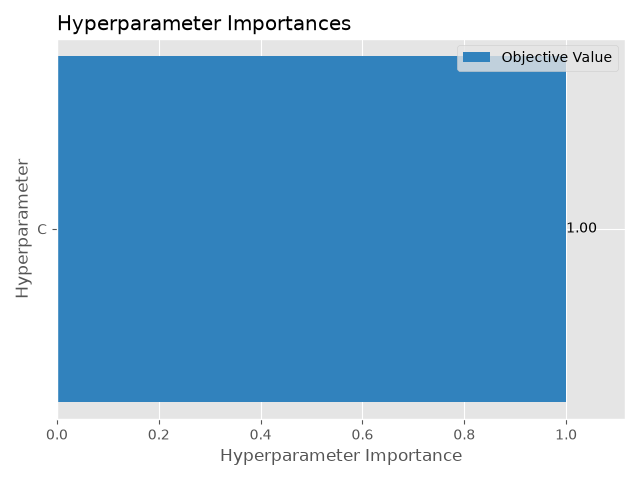

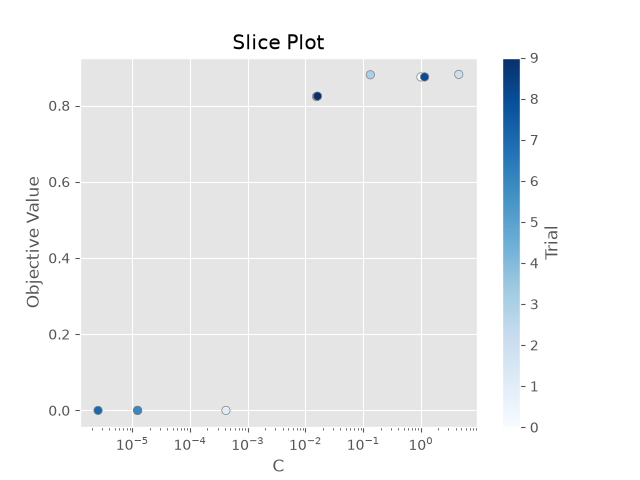

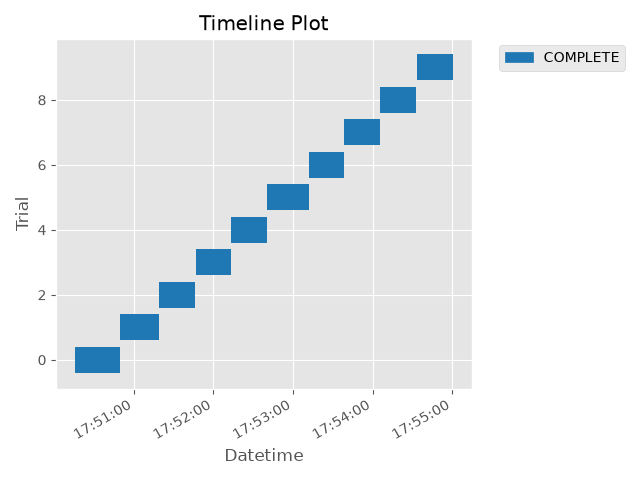

In [27]:
export_dir = Path(tempfile.mkdtemp())
optuna_qc.plot_optuna_qc(study=tuner.study, export_dir=export_dir)
# a contour plot needs at least two tuned hyperparameters
skip = set() if len(tuner.study.best_params) > 1 else {"optuna_contour.png"}
for png in sorted(export_dir.glob("*.png")):
    if png.name not in skip:
        display(Image(filename=png))

## Hyperparameter Optimization with nested CV
When we optimize the hyperparameters, we use a cross validation approach. Based on performance in the cross validations we choose the best set of hyperparameters. The selection of the best hyperparameters is based on the full data, so we do not really evaluate the tuning process itself. 

To properly evaluate the performance of the tuning we need to include the hyperparameter tuning in the evaluation too. 

For this we make use of a nested cross validation.

In [28]:
# make an outer cv split to be used for the outer cross validation
cv_outer = KFold(n_splits=2, random_state=42, shuffle=True)

# now run the nested cross validation with tuning in the inner fold
cv_table: pd.DataFrame = mother_takes_care.mother_cv(
    model,
    tuner=tuner,
    inner_cv=cv,
    cv=cv_outer,
    groups=groups["tanimoto-group"],
    X=features,
    y=data["p_np"],
)
cv_table

INFO:mother.pipeline_utils:Starting cross validation...
.venv/lib/python3.12/site-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(
INFO:mother.optimization.core:Setting up Optuna to optimize hyperparameters with direction: 2
INFO:optuna.storages._in_memory:A new study created in memory with name: no-name-0af1a729-8440-400b-ba96-92f6b78f119f
INFO:mother.optimization.core:Running hyperparameter optimization with 10 trials
INFO:mother.optimization.core:Trial 0, cv score: [0.86792453 0.90526316 0.83809524 0.86538462 0.81395349]
src/mother/optimization/core.py:314: FutureWarning: `optuna.terminator` module has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.9.0.
  report_cross_validation_scores(trial, list(cv_score_not_na))
INFO:optuna.study.study:Trial 0 finished with value: 0.858124205609714 and parameters: {'ml_model__C': 1.0}. Best is trial 0 with 

{'ml_model__C': 6.156997328235206}


INFO:mother.optimization.core:Training completed
INFO:mother.optimization.core:Setting up Optuna to optimize hyperparameters with direction: 2
INFO:optuna.storages._in_memory:A new study created in memory with name: no-name-3a9097b2-4a8a-418a-8e63-01cb811fd429
INFO:mother.optimization.core:Running hyperparameter optimization with 10 trials
INFO:mother.optimization.core:Trial 0, cv score: [0.9122807  0.95412844 0.87619048 0.87640449 0.88659794]
src/mother/optimization/core.py:314: FutureWarning: `optuna.terminator` module has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.9.0.
  report_cross_validation_scores(trial, list(cv_score_not_na))
INFO:optuna.study.study:Trial 0 finished with value: 0.9011204101676373 and parameters: {'ml_model__C': 1.0}. Best is trial 0 with value: 0.9011204101676373.
INFO:mother.optimization.core:Trial 1, cv score: [0. 0. 0. 0. 0.]
src/mother/optimization/core.py:314: FutureWarning: `optu

{'ml_model__C': 0.3134958021096912}


INFO:mother.optimization.core:Training completed
INFO:mother.pipeline_utils:Cross validation completed
INFO:mother.pipeline_utils:Returning performance_data only


,pred_p_np,pred_proba_0,pred_proba_1,pred_total_uncertainty,p_np,cv_group,iteration,test_index
0,1,0.000613,0.999387,0.005144,1,0,0,0
1,1,0.026681,0.973319,0.123009,1,1,1,1
2,1,0.000613,0.999387,0.005144,1,0,0,2
3,1,0.017851,0.982149,0.089553,1,2,1,3
4,1,0.017381,0.982619,0.087665,1,2,1,4
...,...,...,...,...,...,...,...,...
652,1,0.00005,0.99995,0.000548,1,270,0,652
653,1,0.005268,0.994732,0.032889,1,271,0,653
654,0,0.652578,0.347422,0.645836,1,263,1,654
655,1,0.232464,0.767536,0.542236,1,272,1,655
